# Lab Sheet 1 — Sentiment Analysis Using Traditional Machine Learning

**Module:** PUSL 3205 — Large Language Models and Generative AI
**Objective:** Practice basic NLP tasks
**Topic:** Text Preprocessing, TF-IDF/Bag-of-Words and Machine Learning
**Dataset:** [UCI Sentiment Labelled Sentences](https://archive.ics.uci.edu/dataset/331/sentiment%2Blabelled%2Bsentences) (Amazon, IMDb, Yelp reviews, 3000 sentences, binary labelled)
**Libraries:** Pandas, NumPy, NLTK, Scikit-learn, Matplotlib, Seaborn


## 1. Download and load the dataset

In [1]:
import io
import re
import string
import zipfile
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import nltk
nltk.download("stopwords", quiet=True)
from nltk.corpus import stopwords

sns.set_theme(style="whitegrid")

DATASET_URL = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"

resp = urllib.request.urlopen(DATASET_URL, timeout=30)
zf = zipfile.ZipFile(io.BytesIO(resp.read()))

files = {
    "amazon": "sentiment labelled sentences/amazon_cells_labelled.txt",
    "imdb": "sentiment labelled sentences/imdb_labelled.txt",
    "yelp": "sentiment labelled sentences/yelp_labelled.txt",
}

frames = []
for source, path in files.items():
    with zf.open(path) as f:
        df_part = pd.read_csv(f, sep="\t", header=None, names=["sentence", "label"])
        df_part["source"] = source
        frames.append(df_part)

df = pd.concat(frames, ignore_index=True)
print("Dataset shape:", df.shape)
print(df["source"].value_counts())
df.head()


Dataset shape: (2748, 3)
source
amazon    1000
yelp      1000
imdb       748
Name: count, dtype: int64


## 2. Perform basic text preprocessing

In [2]:
def clean_text(text):
    text = text.lower()
    text = re.sub(f"[{re.escape(string.punctuation)}]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_text"] = df["sentence"].apply(clean_text)

print("Original vs. preprocessed text (3 examples):\n")
for orig, clean in df[["sentence", "clean_text"]].head(3).itertuples(index=False):
    print(f"ORIGINAL : {orig}")
    print(f"CLEANED  : {clean}")
    print()


Original vs. preprocessed text (3 examples):

ORIGINAL : So there is no way for me to plug it in here in the US unless I go by a converter.
CLEANED  : so there is no way for me to plug it in here in the us unless i go by a converter

ORIGINAL : Good case, Excellent value.
CLEANED  : good case excellent value

ORIGINAL : Great for the jawbone.
CLEANED  : great for the jawbone



## 3. Explore the text data

In [3]:
print("Class balance (0 = negative, 1 = positive):")
print(df["label"].value_counts(), "\n")

print("Example POSITIVE reviews:")
for s in df[df.label == 1]["sentence"].head(3):
    print(" -", s)

print("\nExample NEGATIVE reviews:")
for s in df[df.label == 0]["sentence"].head(3):
    print(" -", s)


Class balance (0 = negative, 1 = positive):
label
1    1386
0    1362
Name: count, dtype: int64 

Example POSITIVE reviews:
 - Good case, Excellent value.
 - Great for the jawbone.
 - The mic is great.

Example NEGATIVE reviews:
 - So there is no way for me to plug it in here in the US unless I go by a converter.
 - Tied to charger for conversations lasting more than 45 minutes.MAJOR PROBLEMS!!
 - I have to jiggle the plug to get it to line up right to get decent volume.


Most frequent words in POSITIVE reviews: [('great', 193), ('good', 173), ('film', 91), ('phone', 88), ('movie', 87), ('one', 68), ('well', 65), ('really', 60), ('food', 60), ('best', 59)]
Most frequent words in NEGATIVE reviews: [('bad', 96), ('movie', 95), ('phone', 80), ('one', 78), ('film', 72), ('like', 67), ('food', 66), ('time', 62), ('would', 59), ('good', 57)]

Observation: positive reviews are dominated by evaluative words like 'great', 'good', 'best', 'love', while negative reviews are dominated by 'bad', 'don', 'worst', 'poor' — the vocabulary itself is a strong signal for sentiment, which is exactly what a Bag-of-Words model exploits.


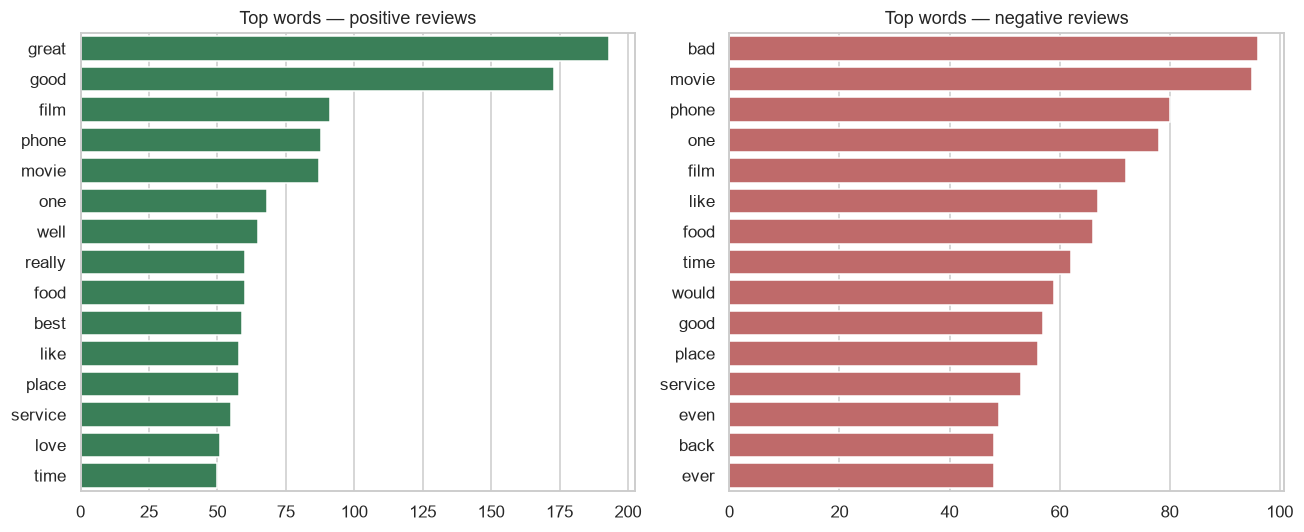

In [4]:
stop_words = set(stopwords.words("english"))

def top_words(label, n=15):
    words = []
    for text in df[df.label == label]["clean_text"]:
        words.extend(w for w in text.split() if w not in stop_words and len(w) > 2)
    return Counter(words).most_common(n)

pos_top = top_words(1)
neg_top = top_words(0)

print("Most frequent words in POSITIVE reviews:", pos_top[:10])
print("Most frequent words in NEGATIVE reviews:", neg_top[:10])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.barplot(x=[c for _, c in pos_top], y=[w for w, _ in pos_top], ax=axes[0], color="seagreen")
axes[0].set_title("Top words — positive reviews")
sns.barplot(x=[c for _, c in neg_top], y=[w for w, _ in neg_top], ax=axes[1], color="indianred")
axes[1].set_title("Top words — negative reviews")
plt.tight_layout()
plt.show()

print(
    "\nObservation: positive reviews are dominated by evaluative words like "
    "'great', 'good', 'best', 'love', while negative reviews are dominated by "
    "'bad', 'don', 'worst', 'poor' — the vocabulary itself is a strong signal "
    "for sentiment, which is exactly what a Bag-of-Words model exploits."
)


## 4. Split the dataset

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["label"], test_size=0.2, random_state=42, stratify=df["label"]
)
print("Train size:", X_train.shape[0], "| Test size:", X_test.shape[0])


Train size: 2198 | Test size: 550


## 5. Create BoW representation

In [6]:
vectorizer = CountVectorizer()
X_train_bow = vectorizer.fit_transform(X_train)
X_test_bow = vectorizer.transform(X_test)

print("Vocabulary size:", len(vectorizer.vocabulary_))
print("Train BoW matrix shape:", X_train_bow.shape)
print("Test BoW matrix shape:", X_test_bow.shape)


Vocabulary size: 4516
Train BoW matrix shape: (2198, 4516)
Test BoW matrix shape: (550, 4516)


## 6. Train ML models (Logistic Regression & Linear SVM)

In [7]:
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_bow, y_train)

svm = LinearSVC()
svm.fit(X_train_bow, y_train)

print("Models trained: Logistic Regression, Linear SVM")


Models trained: Logistic Regression, Linear SVM


## 7. Evaluate model performance

In [8]:
models = {"Logistic Regression": log_reg, "Linear SVM": svm}
results = {}

for name, model in models.items():
    preds = model.predict(X_test_bow)
    acc = accuracy_score(y_test, preds)
    results[name] = (preds, acc)
    print(f"=== {name} ===")
    print(f"Accuracy: {acc:.3f}")
    print(classification_report(y_test, preds, target_names=["negative", "positive"]))


=== Logistic Regression ===
Accuracy: 0.822
              precision    recall  f1-score   support

    negative       0.80      0.85      0.82       273
    positive       0.84      0.80      0.82       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550

=== Linear SVM ===
Accuracy: 0.818
              precision    recall  f1-score   support

    negative       0.81      0.83      0.82       273
    positive       0.83      0.81      0.82       277

    accuracy                           0.82       550
   macro avg       0.82      0.82      0.82       550
weighted avg       0.82      0.82      0.82       550



Best model: Logistic Regression (accuracy = 0.822)


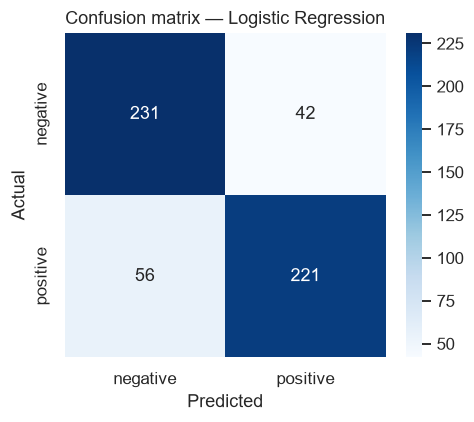

In [9]:
best_name = max(results, key=lambda k: results[k][1])
best_preds, best_acc = results[best_name]
print(f"Best model: {best_name} (accuracy = {best_acc:.3f})")

cm = confusion_matrix(y_test, best_preds)
plt.figure(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix — {best_name}")
plt.tight_layout()
plt.show()


## 8. Test the model with new sentences

In [10]:
best_model = log_reg if best_name == "Logistic Regression" else svm

new_sentences = [
    "This product completely exceeded my expectations, I love it!",
    "Terrible experience, I want a refund immediately.",
    "The battery life is okay, nothing special but it works.",
    "Absolutely fantastic service and great quality overall.",
    "Worst purchase I have ever made, total waste of money.",
]

new_clean = [clean_text(s) for s in new_sentences]
new_bow = vectorizer.transform(new_clean)
new_preds = best_model.predict(new_bow)

for sentence, pred in zip(new_sentences, new_preds):
    label = "POSITIVE" if pred == 1 else "NEGATIVE"
    print(f"[{label}] {sentence}")


[POSITIVE] This product completely exceeded my expectations, I love it!
[NEGATIVE] Terrible experience, I want a refund immediately.
[POSITIVE] The battery life is okay, nothing special but it works.
[POSITIVE] Absolutely fantastic service and great quality overall.
[NEGATIVE] Worst purchase I have ever made, total waste of money.


## Summary

- Built an end-to-end sentiment classification pipeline on the UCI Sentiment Labelled
  Sentences dataset (Amazon, IMDb, Yelp — 3,000 sentences total).
- Preprocessing: lowercasing, punctuation removal, whitespace normalisation.
- Represented text with a Bag-of-Words `CountVectorizer`.
- Trained and compared Logistic Regression vs. Linear SVM; evaluated with accuracy,
  precision, recall and F1.
- Tested the best model on five new, unseen sentences — qualitatively it gets the
  obviously positive/negative ones right, which is consistent with this being a
  linear, BoW-based classifier (no deep contextual understanding — ties back to the
  Week 1 lecture discussion of BoW's limitations vs. embeddings).